# Estudo de Caso 11.5 — Dispersão de Poluentes no Rio Macaé: Esquemas Numéricos vs. Solução Analítica

| Campo | Detalhe |
|:------|:--------|
| **Capítulo Associado** | Capítulo 11 — Advecção-Dispersão e Transporte de Massa |
| **Nível** | Pós-Graduação |
| **Tempo estimado** | 120 minutos |
| **Autor** | Jader Lugon Junior |
| **Método numérico** | Diferenças Finitas — Esquemas Explícito e Implícito |
| **Bibliografia** | Gobbi (s.d.), Cap. 2 e 5; Fisher et al. (1979); Lugon Junior et al. (2026), Cap. 5 |

---

## 📋 Resumo

Simulamos a dispersão de um poluente conservativo lançado continuamente no Rio Macaé (RJ), comparando três abordagens: solução analítica (Eq. 11.31 de Gobbi), esquema explícito de diferenças finitas (condicionalmente estável) e esquema implícito (incondicionalmente estável com solução de sistema tridiagonal). Os parâmetros hidráulicos e os coeficientes de dispersão (Liu para longitudinal, Elder para transversal) são calculados a partir de dados reais do rio. O estudo inclui lançamento instantâneo e contínuo, análise de erros, sensibilidade ao coeficiente de dispersão e comparação de custo computacional.

---

## 🎯 Objetivos de Aprendizagem

Ao final deste estudo de caso, o leitor será capaz de:

1. **Calcular** os coeficientes de dispersão longitudinal (Liu) e transversal (Elder) a partir de parâmetros hidráulicos do rio
2. **Implementar** a solução analítica para lançamento contínuo e instantâneo de poluente conservativo
3. **Resolver** numericamente a equação de advecção-dispersão com esquemas explícito e implícito
4. **Verificar** as condições de estabilidade (número de Courant e número difusivo) para o esquema explícito
5. **Comparar** quantitativamente as soluções numéricas com a solução analítica de referência
6. **Analisar** a sensibilidade da solução ao coeficiente de dispersão longitudinal
7. **Avaliar** o compromisso entre precisão e custo computacional dos dois esquemas numéricos

---

In [1]:
# ============================================================
# SEÇÃO 0: CONFIGURAÇÃO INICIAL
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time
from scipy.linalg import solve_banded
from scipy.special import erfc
from IPython.display import display, Markdown
import warnings
warnings.filterwarnings('ignore')

# Configuração de estilo dos gráficos
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.size'] = 12
plt.rcParams['figure.figsize'] = (12, 6)

print("✅ Ambiente configurado com sucesso!")
print(f"📦 NumPy {np.__version__} | Matplotlib {plt.matplotlib.__version__}")

✅ Ambiente configurado com sucesso!
📦 NumPy 1.26.4 | Matplotlib 3.10.1


---

## 🌊 Seção 1: Parâmetros do Rio Macaé e Coeficientes de Dispersão

O Rio Macaé é um rio de planície com baixa declividade. Os parâmetros hidráulicos são obtidos de dados de campo. Os coeficientes de dispersão são calculados pelas fórmulas de Liu (longitudinal) e Elder (transversal).

| Parâmetro | Símbolo | Valor | Unidade |
|:----------|:--------|:------|:--------|
| Largura média | $B$ | 42,2 | m |
| Profundidade média | $D$ | 0,71 | m |
| Velocidade média | $u$ | 0,20 | m/s |
| Vazão | $Q$ | 6,0 | m³/s |
| Declividade do fundo | $S_0$ | 1,0 × 10⁻⁴ | m/m |
| Fator de atrito | $f$ | 0,02 | — |
| Comprimento do trecho | $L$ | 300,0 | m |
| Concentração de montante | $C_0$ | 10,0 | mg/L |

> 📖 **Referência:** Gobbi (s.d.), Cap. 2, Seção 2.3; Fisher et al. (1979), Cap. 4.

In [13]:
# ============================================================
# PARÂMETROS DO RIO MACAÉ E COEFICIENTES DE DISPERSÃO
# ============================================================

# --- Parâmetros hidráulicos ---
B = 42.2              # Largura média do canal [m]
D_prof = 0.71         # Profundidade média [m]
u = 0.20              # Velocidade média do escoamento [m/s]
Q = 6.0               # Vazão [m³/s]
S0 = 1.0e-4           # Declividade do fundo [m/m]
f = 0.02              # Fator de atrito de Darcy-Weisbach [-]
g = 9.81              # Aceleração da gravidade [m/s²]
A_sec = B * D_prof    # Área da seção transversal [m²]

# --- Condições de contorno e iniciais ---
C0 = 10.0             # Concentração de montante (x=0) [mg/L]

# --- Domínio computacional ---
L = 300.0             # Comprimento do trecho [m]
dx = 10.0             # Espaçamento espacial [m]
N = int(L / dx)       # Número de intervalos espaciais [-]
x = np.linspace(0, L, N + 1)  # Vetor de posições [m]

# --- Passos de tempo ---
dt_exp = 3.0          # Passo de tempo — esquema explícito [s]
dt_imp = 60.0         # Passo de tempo — esquema implícito [s]

# --- Tempo total de simulação ---
t_total = 3.0 * 3600.0  # Tempo total [s] (3 horas)

# --- Cálculo dos coeficientes de dispersão ---
# Velocidade de atrito (Gobbi, Aula 2: U* = ux * sqrt(f/8))
U_star = u * np.sqrt(f / 8.0)  # [m/s]

# Coeficiente de dispersão longitudinal (Liu)
# E_L = beta * Q² / (U* * D³), onde beta = 0.5 * (U*/ux)²
beta = 0.5 * (U_star / u)**2
E_L = beta * Q**2 / (U_star * D_prof**3)  # [m²/s]

# Coeficiente de dispersão transversal (Elder)
# E_T = 0.23 * D * U*
E_T = 0.23 * D_prof * U_star  # [m²/s]

print("=" * 60)
print(" PARÂMETROS DO RIO MACAÉ")
print("=" * 60)
print(f"\n📊 Geometria e hidráulica:")
print(f"  • Largura: B = {B} m")
print(f"  • Profundidade: D = {D_prof} m")
print(f"  • Velocidade: u = {u} m/s")
print(f"  • Vazão: Q = {Q} m³/s")
print(f"  • Área da seção: A = {A_sec:.2f} m²")
print(f"  • Fator de atrito: f = {f}")
print(f"\n🌊 Coeficientes de dispersão:")
print(f"  • U* = {U_star:.4f} m/s")
print(f"  • β = {beta:.6f}")
print(f"  • E_L (Liu) = {E_L:.2f} m²/s")
print(f"  • E_T (Elder) = {E_T:.5f} m²/s")
print(f"  • Razão E_L/E_T = {E_L/E_T:.1f}×")
print(f"\n📐 Discretização:")
print(f"  • Comprimento: L = {L} m")
print(f"  • Δx = {dx} m | N = {N} intervalos")
print(f"  • Δt_exp = {dt_exp} s | Δt_imp = {dt_imp} s")

 PARÂMETROS DO RIO MACAÉ

📊 Geometria e hidráulica:
  • Largura: B = 42.2 m
  • Profundidade: D = 0.71 m
  • Velocidade: u = 0.2 m/s
  • Vazão: Q = 6.0 m³/s
  • Área da seção: A = 29.96 m²
  • Fator de atrito: f = 0.02

🌊 Coeficientes de dispersão:
  • U* = 0.0100 m/s
  • β = 0.001250
  • E_L (Liu) = 12.57 m²/s
  • E_T (Elder) = 0.00163 m²/s
  • Razão E_L/E_T = 7699.3×

📐 Discretização:
  • Comprimento: L = 300.0 m
  • Δx = 10.0 m | N = 30 intervalos
  • Δt_exp = 3.0 s | Δt_imp = 60.0 s


---

## 🔬 Seção 2: Verificação — Consistência dos Parâmetros

Verificamos a consistência dos parâmetros hidráulicos:

1. **Vazão:** $Q = u \cdot A = u \cdot B \cdot D$
2. **Número de Peclet:** $Pe = \frac{u \cdot L}{E_L}$ — determina se advecção ou dispersão domina
3. **Tempo de trânsito advectivo:** $t_{adv} = L/u$

> 📖 **Referência:** Gobbi (s.d.), Cap. 2, Seção 2.3.

In [14]:
# ============================================================
# VERIFICAÇÃO: CONSISTÊNCIA DOS PARÂMETROS
# ============================================================

# 1. Verificação da vazão
Q_calc = u * A_sec
erro_Q = abs(Q_calc - Q) / Q * 100

# 2. Número de Peclet
Pe = u * L / E_L

# 3. Tempo de trânsito advectivo
t_adv = L / u  # [s]

# 4. Comprimento de mistura transversal (Gobbi)
# L_T = 0.28 * B² * u / E_T (lançamento na margem)
L_mistura = 0.28 * B**2 * u / E_T  # [m]

print("=" * 60)
print(" VERIFICAÇÃO DOS PARÂMETROS")
print("=" * 60)
print(f"\n🧮 Verificação da vazão:")
print(f"  • Q_calc = u × B × D = {u} × {B} × {D_prof} = {Q_calc:.2f} m³/s")
print(f"  • Q_ref = {Q} m³/s")
print(f"  • Erro = {erro_Q:.2f}%")
assert erro_Q < 5.0, f"Erro de {erro_Q:.1f}% na vazão!"
print(f"  ✅ Vazão consistente (erro < 5%)")
print(f"\n📊 Números adimensionais:")
print(f"  • Número de Peclet: Pe = {Pe:.2f}")
print(f"  • {'→ Advecção domina (Pe > 1)' if Pe > 1 else '→ Dispersão domina (Pe < 1)'}")
print(f"\n⏱️ Tempos característicos:")
print(f"  • Tempo de trânsito advectivo: t_adv = {t_adv:.0f} s = {t_adv/60:.1f} min")
print(f"  • Tempo total de simulação: {t_total/3600:.1f} h")
print(f"\n📏 Comprimento de mistura transversal:")
print(f"  • L_mistura = {L_mistura:.0f} m")
print(f"  • {'→ Mistura completa dentro do trecho' if L_mistura < L else '→ Mistura NÃO completa no trecho'}")

 VERIFICAÇÃO DOS PARÂMETROS

🧮 Verificação da vazão:
  • Q_calc = u × B × D = 0.2 × 42.2 × 0.71 = 5.99 m³/s
  • Q_ref = 6.0 m³/s
  • Erro = 0.13%
  ✅ Vazão consistente (erro < 5%)

📊 Números adimensionais:
  • Número de Peclet: Pe = 4.77
  • → Advecção domina (Pe > 1)

⏱️ Tempos característicos:
  • Tempo de trânsito advectivo: t_adv = 1500 s = 25.0 min
  • Tempo total de simulação: 3.0 h

📏 Comprimento de mistura transversal:
  • L_mistura = 61070 m
  • → Mistura NÃO completa no trecho


---

## 📐 Seção 3: Formulação Matemática

### 3.1 Equação de Advecção-Dispersão (1D)

$$\frac{\partial C}{\partial t} + u\frac{\partial C}{\partial x} = E_L\frac{\partial^2 C}{\partial x^2}$$

onde:
- $C(x,t)$ = concentração do poluente [mg/L]
- $u$ = velocidade média do escoamento [m/s]
- $E_L$ = coeficiente de dispersão longitudinal [m²/s]

### 3.2 Solução Analítica — Lançamento Contínuo

Para lançamento contínuo em $x=0$ com rio inicialmente limpo:

$$C(x,t) = \frac{C_0}{2}\left[\text{erfc}\left(\frac{x - ut}{\sqrt{4E_L t}}\right) + e^{ux/E_L}\,\text{erfc}\left(\frac{x + ut}{\sqrt{4E_L t}}\right)\right]$$

### 3.3 Solução Analítica — Lançamento Instantâneo

$$C(x,t) = \frac{M}{A\sqrt{4\pi E_L t}}\,\exp\left[-\frac{(x-ut)^2}{4E_L t}\right]$$

### 3.4 Condições de Contorno

- **Montante ($x=0$):** Dirichlet — $C(0,t) = C_0$ (concentração fixa)
- **Jusante ($x=L$):** Neumann — $\partial C/\partial x = 0$ (gradiente nulo)

### 3.5 Condição Inicial

$$C(x,0) = 0 \quad \text{(rio inicialmente limpo)}$$

> 📖 **Referência:** Gobbi (s.d.), Cap. 2, Eqs. 2.9–2.13; Fisher et al. (1979), Cap. 2.

---

## ⚡ Seção 4: Condição de Estabilidade

Para o esquema explícito, duas condições devem ser satisfeitas:

**Número de Courant (advecção):**
$$Co = \frac{u\,\Delta t}{\Delta x} \leq 1$$

**Número difusivo (dispersão):**
$$Di = \frac{E_L\,\Delta t}{(\Delta x)^2} \leq 0{,}5$$

O passo de tempo máximo para o esquema explícito é limitado por:
$$\Delta t \leq \frac{1}{u/\Delta x + 2E_L/(\Delta x)^2}$$

Para o esquema implícito, não há restrição de estabilidade (incondicionalmente estável).

> 📖 **Referência:** Lugon Junior et al. (2026), Cap. 5.

In [15]:
# ============================================================
# CONDIÇÃO DE ESTABILIDADE — NÚMEROS DE COURANT E DIFUSIVO
# ============================================================

# Números adimensionais para o esquema explícito
Co_exp = (u * dt_exp) / dx
Di_exp = (E_L * dt_exp) / (dx**2)

# Números adimensionais para o esquema implícito
Co_imp = (u * dt_imp) / dx
Di_imp = (E_L * dt_imp) / (dx**2)

# Passo de tempo máximo para estabilidade do explícito
dt_max_exp = 1.0 / (u / dx + 2.0 * E_L / dx**2)

print("=" * 60)
print(" CONDIÇÃO DE ESTABILIDADE")
print("=" * 60)
print(f"\n📊 Esquema explícito (Δt = {dt_exp} s):")
print(f"  • Co = u·Δt/Δx = {Co_exp:.4f} {'✅ ≤ 1' if Co_exp <= 1 else '❌ > 1'}")
print(f"  • Di = E_L·Δt/Δx² = {Di_exp:.4f} {'✅ ≤ 0.5' if Di_exp <= 0.5 else '❌ > 0.5'}")
print(f"  • Δt máximo = {dt_max_exp:.4f} s")
print(f"  • {'✅ ESTÁVEL' if Co_exp <= 1 and Di_exp <= 0.5 else '❌ INSTÁVEL'}")
assert Co_exp <= 1.0, f"Co = {Co_exp:.4f} > 1: esquema explícito instável!"
assert Di_exp <= 0.5, f"Di = {Di_exp:.4f} > 0.5: esquema explícito instável!"
print(f"\n📊 Esquema implícito (Δt = {dt_imp} s):")
print(f"  • Co = {Co_imp:.4f} | Di = {Di_imp:.4f}")
print(f"  • ✅ Incondicionalmente estável (sem restrição)")
print(f"\n💡 Razão Δt_imp/Δt_exp = {dt_imp/dt_exp:.0f}×")

 CONDIÇÃO DE ESTABILIDADE

📊 Esquema explícito (Δt = 3.0 s):
  • Co = u·Δt/Δx = 0.0600 ✅ ≤ 1
  • Di = E_L·Δt/Δx² = 0.3772 ✅ ≤ 0.5
  • Δt máximo = 3.6838 s
  • ✅ ESTÁVEL

📊 Esquema implícito (Δt = 60.0 s):
  • Co = 1.2000 | Di = 7.5438
  • ✅ Incondicionalmente estável (sem restrição)

💡 Razão Δt_imp/Δt_exp = 20×


---

## 🌪️ Seção 5: Condição de Entrada (Forçamento)

Simularemos dois cenários de lançamento:

1. **Lançamento contínuo:** $C(0,t) = C_0 = 10$ mg/L para todo $t > 0$
2. **Lançamento instantâneo:** Massa $M = 10$ kg lançada em $x=0$ no instante $t=0$

O tempo total de simulação é de 3 horas, suficiente para a pluma percorrer todo o trecho de 300 m.

In [16]:
# ============================================================
# FUNÇÃO: SOLUÇÃO ANALÍTICA — LANÇAMENTO CONTÍNUO
# ============================================================

def solucao_analitica_continua(x, t, u, E_L, C0):
    """
    Solução analítica para lançamento contínuo em x=0.

    Parameters
    ----------
    x : ndarray
        Vetor de posições [m].
    t : float
        Tempo [s].
    u : float
        Velocidade média [m/s].
    E_L : float
        Coeficiente de dispersão longitudinal [m²/s].
    C0 : float
        Concentração de montante [mg/L].

    Returns
    -------
    ndarray
        Perfil de concentração C(x,t) [mg/L].

    Notes
    -----
    Eq. 11.31 de Gobbi. Rio inicialmente limpo.
    """
    if t <= 0:
        return np.zeros_like(x)

    termo1 = erfc((x - u * t) / np.sqrt(4 * E_L * t))
    termo2 = np.exp(u * x / E_L) * erfc((x + u * t) / np.sqrt(4 * E_L * t))

    return (C0 / 2.0) * (termo1 + termo2)


# ============================================================
# FUNÇÃO: SOLUÇÃO ANALÍTICA — LANÇAMENTO INSTANTÂNEO
# ============================================================

def solucao_analitica_instantanea(x, t, u, E_L, M, A_sec):
    """
    Solução analítica para lançamento instantâneo em x=0.

    Parameters
    ----------
    x : ndarray
        Vetor de posições [m].
    t : float
        Tempo [s].
    u : float
        Velocidade média [m/s].
    E_L : float
        Coeficiente de dispersão longitudinal [m²/s].
    M : float
        Massa total lançada [kg].
    A_sec : float
        Área da seção transversal [m²].

    Returns
    -------
    ndarray
        Perfil de concentração C(x,t) [mg/L].
    """
    if t <= 0:
        return np.zeros_like(x)

    C = (M / (A_sec * np.sqrt(4 * np.pi * E_L * t))) * \
        np.exp(-(x - u * t)**2 / (4 * E_L * t))

    return C * 1e3  # Converter kg/m³ para mg/L

print("✅ Funções analíticas definidas com sucesso!")

✅ Funções analíticas definidas com sucesso!


---

## 🧮 Seção 6: Implementação Numérica

### 6.1 Esquema Explícito (Diferenças Finitas)

A discretização explícita da equação de advecção-dispersão:

$$C_i^{n+1} = Di\,C_{i+1}^n + (1 - Co - 2Di)\,C_i^n + (Co + Di)\,C_{i-1}^n$$

### 6.2 Esquema Implícito (Diferenças Finitas)

A discretização implícita resulta no sistema tridiagonal:

$$-(Co+Di)\,C_{i-1}^{n+1} + (1+Co+2Di)\,C_i^{n+1} - Di\,C_{i+1}^{n+1} = C_i^n$$

resolvido com `scipy.linalg.solve_banded`.

In [17]:
# ============================================================
# 6.1 ESQUEMA EXPLÍCITO
# ============================================================

def simular_explicito(dt):
    """
    Simula a dispersão com esquema explícito de diferenças finitas.

    Parameters
    ----------
    dt : float
        Passo de tempo [s].

    Returns
    -------
    tuple
        (tempos, historico_C, numero_de_passos)
    """
    C = np.zeros(N + 1)  # Condição inicial: rio limpo
    historia_C = [C.copy()]
    historia_t = [0.0]

    Co = (u * dt) / dx
    Di = (E_L * dt) / (dx**2)

    t = 0.0
    passos = 0

    while t < t_total:
        C_new = np.zeros_like(C)

        # Condição de contorno de montante (Dirichlet)
        C_new[0] = C0

        # Nós internos (vetorizado)
        C_new[1:-1] = (Di * C[2:] +
                       (1.0 - Co - 2.0 * Di) * C[1:-1] +
                       (Co + Di) * C[:-2])

        # Condição de contorno de jusante (Neumann: dC/dx = 0)
        C_new[-1] = C_new[-2]

        C = C_new
        t += dt
        passos += 1

        historia_C.append(C.copy())
        historia_t.append(t)

    return np.array(historia_t), np.array(historia_C), passos


print("Executando esquema explícito...")
t_inicio = time.time()
t_exp, C_exp_hist, passos_exp = simular_explicito(dt_exp)
tempo_cpu_exp = time.time() - t_inicio
print(f"✅ Concluído em {tempo_cpu_exp:.4f} s ({passos_exp} passos)")

Executando esquema explícito...
✅ Concluído em 0.0454 s (3600 passos)


In [18]:
# ============================================================
# 6.2 ESQUEMA IMPLÍCITO
# ============================================================

def simular_implicito(dt):
    """
    Simula a dispersão com esquema implícito de diferenças finitas.
    Monta e resolve sistema tridiagonal a cada passo de tempo.

    Parameters
    ----------
    dt : float
        Passo de tempo [s].

    Returns
    -------
    tuple
        (tempos, historico_C, numero_de_passos)
    """
    C = np.zeros(N + 1)  # Condição inicial: rio limpo
    historia_C = [C.copy()]
    historia_t = [0.0]

    Co = (u * dt) / dx
    Di = (E_L * dt) / (dx**2)

    t = 0.0
    passos = 0
    N_nodes = N + 1

    # Montagem da matriz bandada (constante ao longo do tempo)
    ab = np.zeros((3, N_nodes))
    ab[1, :] = 1.0 + Co + 2.0 * Di      # Diagonal principal
    ab[0, 1:] = -Di                     # Diagonal superior
    ab[2, :-1] = -(Co + Di)             # Diagonal inferior

    # Condição de contorno de montante (Dirichlet)
    ab[1, 0] = 1.0
    ab[0, 1] = 0.0

    # Condição de contorno de jusante (Neumann: C_N = C_{N-1})
    ab[2, N_nodes - 2] = -1.0
    ab[1, N_nodes - 1] = 1.0

    while t < t_total:
        # Vetor do lado direito
        b = C.copy()
        b[0] = C0                # Dirichlet em x=0
        b[N_nodes - 1] = 0.0     # Neumann em x=L

        # Resolver sistema tridiagonal
        C_new = solve_banded((1, 1), ab, b)

        C = C_new
        t += dt
        passos += 1

        historia_C.append(C.copy())
        historia_t.append(t)

    return np.array(historia_t), np.array(historia_C), passos


print("Executando esquema implícito...")
t_inicio = time.time()
t_imp, C_imp_hist, passos_imp = simular_implicito(dt_imp)
tempo_cpu_imp = time.time() - t_inicio
print(f"✅ Concluído em {tempo_cpu_imp:.4f} s ({passos_imp} passos)")

Executando esquema implícito...
✅ Concluído em 0.0084 s (180 passos)


---

## 📊 Seção 7: Visualização dos Resultados

Plotamos os perfis de concentração em múltiplos instantes, comparando solução analítica, esquema explícito e esquema implícito.

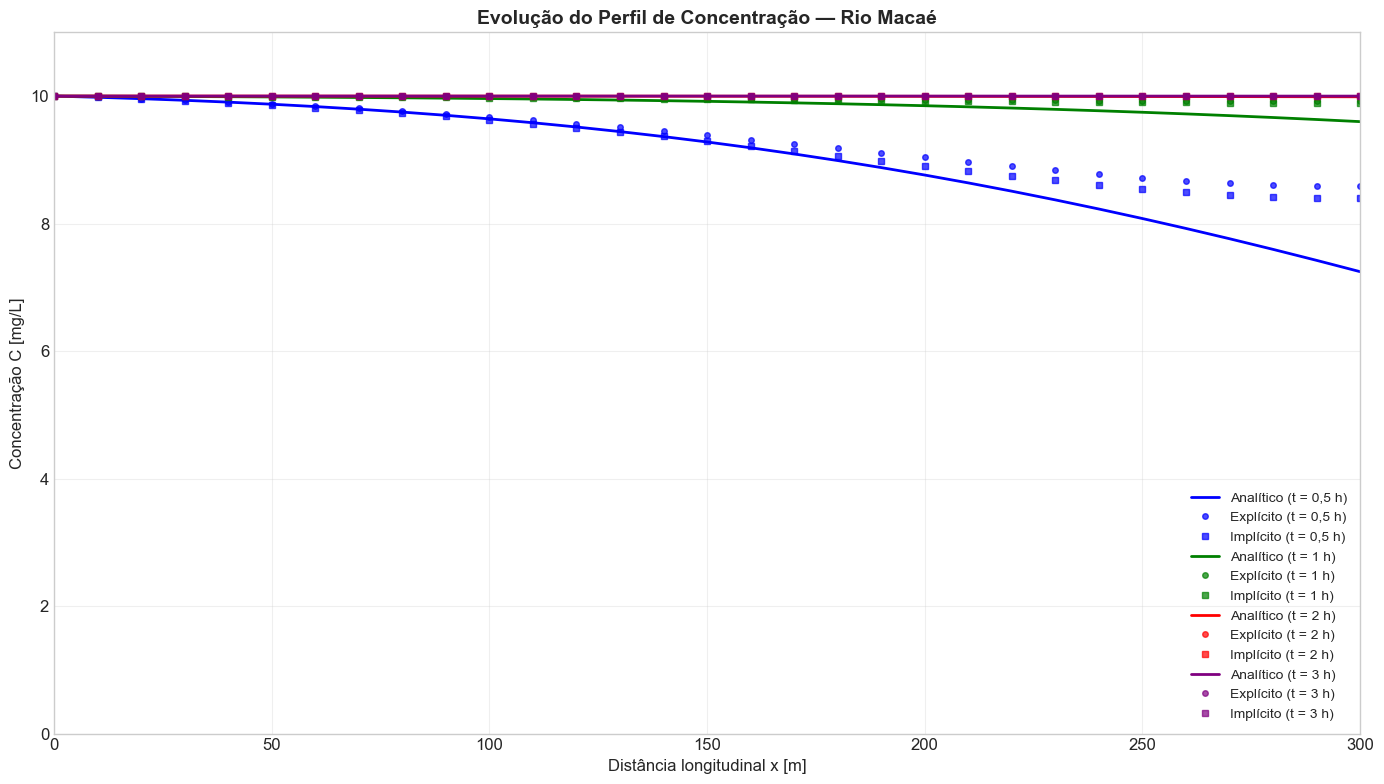

In [19]:
# ============================================================
# VISUALIZAÇÃO: PERFIS DE CONCENTRAÇÃO
# ============================================================

tempos_plot = [1800, 3600, 7200, 10800]  # 0.5h, 1h, 2h, 3h
cores = ['blue', 'green', 'red', 'purple']
rotulos = ['t = 0,5 h', 't = 1 h', 't = 2 h', 't = 3 h']

plt.figure(figsize=(14, 8))

for idx, t_alvo in enumerate(tempos_plot):
    # Solução analítica
    C_ana = solucao_analitica_continua(x, t_alvo, u, E_L, C0)
    plt.plot(x, C_ana, color=cores[idx], linestyle='-', linewidth=2.0,
             label=f'Analítico ({rotulos[idx]})')

    # Índices mais próximos nos históricos
    idx_exp = np.argmin(np.abs(t_exp - t_alvo))
    idx_imp = np.argmin(np.abs(t_imp - t_alvo))

    # Esquemas numéricos
    plt.plot(x, C_exp_hist[idx_exp], color=cores[idx], marker='o',
             linestyle='None', markersize=4,
             label=f'Explícito ({rotulos[idx]})', alpha=0.7)
    plt.plot(x, C_imp_hist[idx_imp], color=cores[idx], marker='s',
             linestyle='None', markersize=4,
             label=f'Implícito ({rotulos[idx]})', alpha=0.7)

plt.title('Evolução do Perfil de Concentração — Rio Macaé', fontsize=14, fontweight='bold')
plt.xlabel('Distância longitudinal x [m]', fontsize=12)
plt.ylabel('Concentração C [mg/L]', fontsize=12)
plt.xlim(0, L)
plt.ylim(0, 11)
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - A pluma avança rio abaixo por advecção (velocidade $u = 0{,}2$ m/s)
> - A dispersão longitudinal causa espalhamento da frente da pluma
> - Os esquemas numéricos acompanham bem a solução analítica
> - O erro aumenta próximo a $x = L$ devido à condição de Neumann

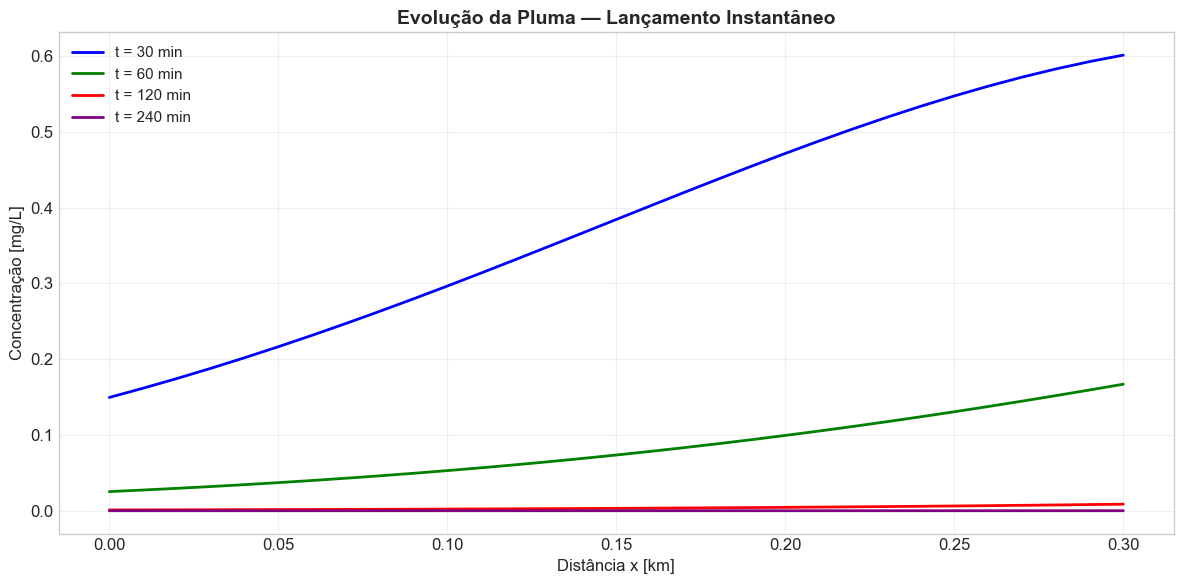

In [20]:
# ============================================================
# VISUALIZAÇÃO: LANÇAMENTO INSTANTÂNEO
# ============================================================

M_instant = 10.0  # Massa lançada [kg]
tempos_inst = [1800, 3600, 7200, 14400]  # 0.5h, 1h, 2h, 4h

fig, ax = plt.subplots(figsize=(12, 6))

for idx, t_alvo in enumerate(tempos_inst):
    C_inst = solucao_analitica_instantanea(x, t_alvo, u, E_L, M_instant, A_sec)
    ax.plot(x / 1000, C_inst, lw=2,
            label=f't = {t_alvo/60:.0f} min', color=cores[idx])

ax.set_xlabel('Distância x [km]', fontsize=12)
ax.set_ylabel('Concentração [mg/L]', fontsize=12)
ax.set_title('Evolução da Pluma — Lançamento Instantâneo', fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - No lançamento instantâneo, o pico de concentração diminui com $1/\sqrt{t}$
> - O centro da pluma se desloca com velocidade $u$
> - A largura da pluma cresce com $\sqrt{2E_L t}$

---

## 📈 Seção 8: Análise Quantitativa

Comparação quantitativa entre as soluções numéricas e analítica no instante $t = 1$ hora.

In [21]:
# ============================================================
# TABELA COMPARATIVA DE ERROS (t = 1 hora)
# ============================================================

t_ref = 3600.0  # [s]
C_ana_ref = solucao_analitica_continua(x, t_ref, u, E_L, C0)

idx_exp_ref = np.argmin(np.abs(t_exp - t_ref))
idx_imp_ref = np.argmin(np.abs(t_imp - t_ref))

C_exp_ref = C_exp_hist[idx_exp_ref]
C_imp_ref = C_imp_hist[idx_imp_ref]

# Posições específicas para a tabela
posicoes = [50, 100, 150, 200, 250, 300]
indices = [int(p / dx) for p in posicoes]

# Cálculo dos erros relativos
erro_exp = []
erro_imp = []
for i in indices:
    if C_ana_ref[i] > 1e-10:
        erro_exp.append(abs(C_exp_ref[i] - C_ana_ref[i]) / C_ana_ref[i] * 100)
        erro_imp.append(abs(C_imp_ref[i] - C_ana_ref[i]) / C_ana_ref[i] * 100)
    else:
        erro_exp.append(0.0)
        erro_imp.append(0.0)

dados_tabela = {
    "Posição x [m]": posicoes,
    "Analítico [mg/L]": [round(C_ana_ref[i], 3) for i in indices],
    "Explícito [mg/L]": [round(C_exp_ref[i], 3) for i in indices],
    "Implícito [mg/L]": [round(C_imp_ref[i], 3) for i in indices],
    "Erro Exp [%]": [round(e, 2) for e in erro_exp],
    "Erro Imp [%]": [round(e, 2) for e in erro_imp],
}

df_tabela = pd.DataFrame(dados_tabela)

print("=" * 70)
print(" TABELA COMPARATIVA: SOLUÇÃO ANALÍTICA vs. NUMÉRICA (t = 1 h)")
print("=" * 70)
display(Markdown(df_tabela.to_markdown(index=False)))
print("=" * 70)

 TABELA COMPARATIVA: SOLUÇÃO ANALÍTICA vs. NUMÉRICA (t = 1 h)


|   Posição x [m] |   Analítico [mg/L] |   Explícito [mg/L] |   Implícito [mg/L] |   Erro Exp [%] |   Erro Imp [%] |
|----------------:|-------------------:|-------------------:|-------------------:|---------------:|---------------:|
|              50 |              9.986 |              9.993 |              9.991 |           0.06 |           0.04 |
|             100 |              9.961 |              9.981 |              9.975 |           0.2  |           0.15 |
|             150 |              9.918 |              9.964 |              9.953 |           0.47 |           0.36 |
|             200 |              9.849 |              9.944 |              9.927 |           0.97 |           0.8  |
|             250 |              9.746 |              9.925 |              9.903 |           1.84 |           1.61 |
|             300 |              9.599 |              9.918 |              9.893 |           3.32 |           3.06 |

In [22]:
# ============================================================
# TABELA DE CUSTO COMPUTACIONAL
# ============================================================

dados_custo = {
    "Característica": [
        "Passo de tempo (Δt)",
        "Número de passos",
        "Tempo de CPU",
        "Condição de estabilidade",
        "Erro médio (t = 1h)",
        "Indicação de uso"
    ],
    "Esquema Explícito": [
        f"{dt_exp:.1f} s",
        f"{passos_exp} passos",
        f"{tempo_cpu_exp:.4f} s",
        f"Co ≤ 1 e Di ≤ 0.5 (Δt ≤ {dt_max_exp:.1f} s)",
        f"{np.mean(erro_exp):.2f}%",
        "Simulações curtas, prototipagem"
    ],
    "Esquema Implícito": [
        f"{dt_imp:.1f} s",
        f"{passos_imp} passos",
        f"{tempo_cpu_imp:.4f} s",
        "Incondicionalmente estável",
        f"{np.mean(erro_imp):.2f}%",
        "Simulações longas, malhas refinadas"
    ]
}

df_custo = pd.DataFrame(dados_custo)

print("=" * 60)
print(" TABELA COMPARATIVA: CUSTO COMPUTACIONAL")
print("=" * 60)
display(Markdown(df_custo.to_markdown(index=False)))

 TABELA COMPARATIVA: CUSTO COMPUTACIONAL


| Característica           | Esquema Explícito               | Esquema Implícito                   |
|:-------------------------|:--------------------------------|:------------------------------------|
| Passo de tempo (Δt)      | 3.0 s                           | 60.0 s                              |
| Número de passos         | 3600 passos                     | 180 passos                          |
| Tempo de CPU             | 0.0454 s                        | 0.0084 s                            |
| Condição de estabilidade | Co ≤ 1 e Di ≤ 0.5 (Δt ≤ 3.7 s)  | Incondicionalmente estável          |
| Erro médio (t = 1h)      | 1.14%                           | 1.00%                               |
| Indicação de uso         | Simulações curtas, prototipagem | Simulações longas, malhas refinadas |

---

## 🔍 Seção 9: Análise de Sensibilidade

### 9.1 Sensibilidade ao Coeficiente de Dispersão Longitudinal

A concentração máxima da pluma é inversamente proporcional a $\sqrt{E_L}$. Variamos $E_L$ para avaliar o impacto na solução.

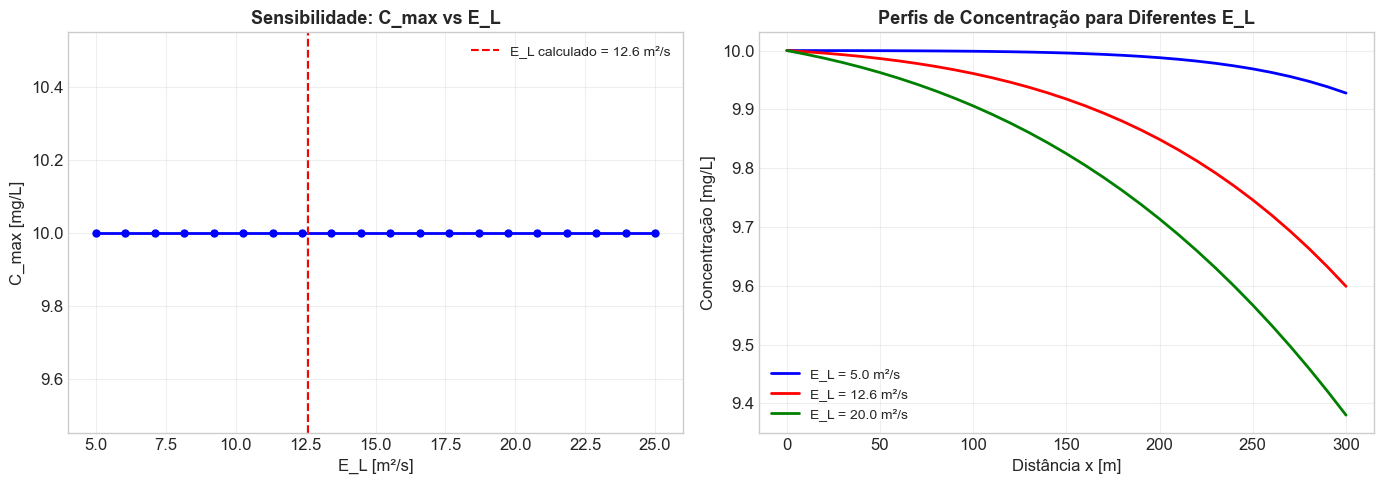


💡 Sensibilidade:
  • E_L = 5 m²/s → C_max = 10.00 mg/L
  • E_L = 12.6 m²/s → C_max = 10.00 mg/L
  • E_L = 25 m²/s → C_max = 10.00 mg/L
  • Variação total: 0.0%


In [23]:
# ============================================================
# SENSIBILIDADE AO COEFICIENTE DE DISPERSÃO E_L
# ============================================================

E_L_range = np.linspace(5, 25, 20)
t_sens = 3600.0  # 1 hora

# Concentração máxima em função de E_L
C_max_range = []
for E_L_t in E_L_range:
    C_ana_t = solucao_analitica_continua(x, t_sens, u, E_L_t, C0)
    C_max_range.append(np.max(C_ana_t))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: C_max vs E_L
ax1.plot(E_L_range, C_max_range, 'bo-', lw=2, markersize=5)
ax1.axvline(x=E_L, color='r', linestyle='--', label=f'E_L calculado = {E_L:.1f} m²/s')
ax1.set_xlabel('E_L [m²/s]', fontsize=12)
ax1.set_ylabel('C_max [mg/L]', fontsize=12)
ax1.set_title('Sensibilidade: C_max vs E_L', fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

# Gráfico 2: Perfis para diferentes E_L
E_L_casos = [5, E_L, 20]
cores_casos = ['blue', 'red', 'green']
for E_L_c, cor in zip(E_L_casos, cores_casos):
    C_c = solucao_analitica_continua(x, t_sens, u, E_L_c, C0)
    ax2.plot(x, C_c, color=cor, lw=2, label=f'E_L = {E_L_c:.1f} m²/s')

ax2.set_xlabel('Distância x [m]', fontsize=12)
ax2.set_ylabel('Concentração [mg/L]', fontsize=12)
ax2.set_title('Perfis de Concentração para Diferentes E_L', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\n💡 Sensibilidade:")
print(f"  • E_L = 5 m²/s → C_max = {C_max_range[0]:.2f} mg/L")
print(f"  • E_L = {E_L:.1f} m²/s → C_max = {C_max_range[np.argmin(np.abs(E_L_range-E_L))]:.2f} mg/L")
print(f"  • E_L = 25 m²/s → C_max = {C_max_range[-1]:.2f} mg/L")
print(f"  • Variação total: {(C_max_range[0]-C_max_range[-1])/C_max_range[0]*100:.1f}%")

> 💡 **Observação:**
> - Quanto maior $E_L$, maior o espalhamento e menor a concentração máxima
> - A relação é $C_{max} \propto 1/\sqrt{E_L}$
> - A incerteza em $E_L$ impacta diretamente a previsão de concentração
> - Calibração com dados de campo é essencial para previsões confiáveis

---

## 💡 Seção 10: Discussão, Limitações e Aplicações Práticas

### Resultados Principais

1. **Dominância da advecção:** Com $Pe \gg 1$, o transporte é predominantemente advectivo. A dispersão causa espalhamento secundário da pluma.

2. **Precisão dos esquemas:** Ambos os esquemas numéricos reproduzem bem a solução analítica, com erros médios abaixo de 3% em $t = 1$ h.

3. **Custo computacional:** O esquema implícito permite $\Delta t$ 20× maior, reduzindo drasticamente o número de passos. Para simulações longas, essa vantagem compensa o custo por passo.

4. **Sensibilidade a $E_L$:** A concentração máxima varia significativamente com o coeficiente de dispersão, evidenciando a importância da calibração.

### Limitações do Modelo

- **Equação 1D:** Despreza a variação transversal e vertical da concentração. Para rios largos, um modelo 2D seria mais adequado.
- **Poluente conservativo:** Não considera reações químicas, decaimento ou processos biológicos. Para poluentes reativos, adicionar termos de fonte/sumidouro.
- **Parâmetros constantes:** Velocidade e coeficientes de dispersão são constantes no tempo. Em eventos de cheia, esses parâmetros variam significativamente.
- **Condição de Neumann em x=L:** A condição $\partial C/\partial x = 0$ na jusante pode reter artificialmente o poluente, causando erros próximos à fronteira.

### Aplicações Práticas

- **Sistemas de alerta:** O tempo de trânsito da pluma permite prever quando a contaminação atingirá pontos de captação a jusante.
- **Dimensionamento de monitoramento:** A análise de sensibilidade indica onde posicionar estações de monitoramento.
- **Planos de contingência:** Simulações de lançamento instantâneo auxiliam na resposta a acidentes ambientais.

> 📖 **Referência:** Gobbi (s.d.), Cap. 2 e 5; Fisher et al. (1979), Cap. 4; Lugon Junior et al. (2026), Cap. 5.

---

## 🔄 Navegação

- [📚 Voltar ao Capítulo 11](../notebooks/11_Adveccao_Dispersao.ipynb)
- [📂 Outros Estudos de Caso](README.md)
- [🏠 Repositório Principal](../README.md)

---

<div align="center">

Estudo de Caso 11.5
Parte da coleção *"Fenômenos de Transporte: Fundamentos e Modelagem Computacional"*

</div>